# Modelado Predictivo: Clasificación con K-Nearest Neighbors (KNN)
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook aplica el clasificador **KNN** del archivo `Knn.py` para predecir la categoría `NSP` a partir de los datos cardiotocográficos. El algoritmo asigna una clase según la mayoría de los **k vecinos más cercanos**, utilizando distancia euclidiana.

### Objetivos del Modelado

1. **Preparación de datos:** Separar las características y la variable objetivo, con **80% para entrenamiento y 20% para prueba** (`seed=42`).
2. **Entrenamiento de KNN:** Estandarizar las características y seleccionar el valor de **k** mediante validación cruzada dentro del conjunto de entrenamiento.
3. **Evaluación:** Obtener exactitud, matriz de confusión, Recall y F1-Score por clase.

In [1]:
# Importación de librerías
import numpy as np  # Operaciones matemáticas, particiones y métricas
import pandas as pd  # Lectura de CSV y presentación de tablas
import matplotlib.pyplot as plt  # Gráficas
from IPython.display import display

# Importación del algoritmo KNN desde su archivo fuente independiente
from Knn import KNNClassifier

# Funciones auxiliares para evaluar las predicciones usando solo NumPy
# Contar aciertos y errores de cada clase (filas: reales; columnas: predichas).
def confusion_matrix(y_true, y_pred, labels):
    """Matriz de confusión con orden de clases explícito."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = np.asarray(labels)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true y y_pred deben tener la misma forma.")

    label_to_index = {label: i for i, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    for real, predicted in zip(y_true, y_pred):
        if real not in label_to_index or predicted not in label_to_index:
            raise ValueError("Se encontró una etiqueta que no está incluida en labels.")
        matrix[label_to_index[real], label_to_index[predicted]] += 1

    return matrix


# Calcular proporción total de predicciones correctas.
def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


# Calcular sensibilidad por clase: TP / (TP + FN).
def recall_per_class(matrix):
    recalls = []
    for i in range(len(matrix)):
        tp = matrix[i, i]
        fn = np.sum(matrix[i, :]) - tp
        recalls.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)
    return np.asarray(recalls)


# Calcular precisión por clase: TP / (TP + FP).
def precision_per_class(matrix):
    precisions = []
    for i in range(len(matrix)):
        tp = matrix[i, i]
        fp = np.sum(matrix[:, i]) - tp
        precisions.append(tp / (tp + fp) if (tp + fp) > 0 else 0.0)
    return np.asarray(precisions)


# Calcular media armónica de precisión y recall para cada clase.
def f1_per_class(precisions, recalls):
    denominator = precisions + recalls
    return np.divide(
        2 * precisions * recalls,
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator != 0
    )

In [2]:
# Carga directa del dataset y separación de características X y objetivo y
df_original = pd.read_csv("CTG_clean.csv")
assert "NSP" in df_original.columns, "No existe la columna NSP."
assert df_original.select_dtypes(include="number").shape[1] == df_original.shape[1], "Hay columnas no numéricas."
assert not df_original.isna().any().any(), "Hay valores faltantes que requieren tratamiento."

# Se retiran duplicados exactos antes de dividir para evitar registros repetidos entre conjuntos
n_duplicados = int(df_original.duplicated().sum())
df = df_original.drop_duplicates().reset_index(drop=True)
X_df = df.drop(columns="NSP")
X = X_df.to_numpy(dtype=float)
y = df["NSP"].to_numpy(dtype=int)
labels = np.unique(y)
names = {1:"Normal", 2:"Sospechoso", 3:"Patológico"}

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42
# Se estratifica por clase con NumPy para conservar aproximadamente sus proporciones
def split_estratificado(y, proporcion_prueba=0.20, seed=42):
    rng = np.random.default_rng(seed)
    idx_train, idx_test = [], []
    for clase in np.unique(y):
        indices = np.flatnonzero(y == clase)
        rng.shuffle(indices)
        n_test = max(1, int(np.round(len(indices) * proporcion_prueba)))
        idx_test.extend(indices[:n_test])
        idx_train.extend(indices[n_test:])
    idx_train = np.array(idx_train, dtype=int)
    idx_test = np.array(idx_test, dtype=int)
    rng.shuffle(idx_train)
    rng.shuffle(idx_test)
    return idx_train, idx_test

idx_train, idx_test = split_estratificado(y, seed=42)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

# Visualización de control, igual que en el notebook de Gradient Boosting
display(X_df.head())
print(f"Registros originales: {len(df_original)} | Duplicados retirados: {n_duplicados}")
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {labels}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,23.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Registros originales: 2126 | Duplicados retirados: 12
Dimensión de Matriz X (Características): (2114, 21)
Dimensión de Vector y (Objetivo NSP):    (2114,)
Entrenamiento: X_train=(1692, 21), y_train=(1692,)
Prueba:        X_test=(422, 21), y_test=(422,)
Clases en y:   [1 2 3]


#### **Entrenamiento de ( KNNClassifier )**

In [3]:
# Comparación de hiperparámetros usando solo el conjunto de entrenamiento.
# Validación cruzada estratificada de 3 particiones: NO se consulta el conjunto de prueba.
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
n_folds = 3
rng = np.random.default_rng(42)
folds = [[] for _ in range(n_folds)]

# Repartir índices de cada clase de forma equilibrada entre los folds
for clase in np.unique(y_train):
    indices = np.flatnonzero(y_train == clase)
    rng.shuffle(indices)
    for j, subset in enumerate(np.array_split(indices, n_folds)):
        folds[j].extend(subset.tolist())
folds = [np.array(fold, dtype=int) for fold in folds]

resultados = []
for k in k_values:
    f1_folds, accuracy_folds = [], []
    for i in range(n_folds):
        # Separar entrenamiento interno y validación del fold
        idx_val = folds[i]
        idx_fit = np.concatenate([folds[j] for j in range(n_folds) if j != i])

        # Estandarizar con media y desviación del entrenamiento interno
        mu = X_train[idx_fit].mean(axis=0)
        sigma = X_train[idx_fit].std(axis=0)
        sigma[sigma == 0] = 1.0
        X_fit_scaled = (X_train[idx_fit] - mu) / sigma
        X_val_scaled = (X_train[idx_val] - mu) / sigma

        # Aplicar el algoritmo del archivo Knn.py sin reescribirlo
        candidato = KNNClassifier(k=k)
        candidato.fit(X_fit_scaled, y_train[idx_fit])
        pred = candidato.predict(X_val_scaled)

        # Calcular métricas de validación
        cm = confusion_matrix(y_train[idx_val], pred, labels=labels)
        precision = precision_per_class(cm)
        recall = recall_per_class(cm)
        f1_folds.append(f1_per_class(precision, recall).mean())
        accuracy_folds.append(accuracy(y_train[idx_val], pred))

    resultados.append({
        "k": k,
        "Exactitud CV (%)": 100 * np.mean(accuracy_folds),
        "F1 macro CV (%)": 100 * np.mean(f1_folds)
    })

comparacion = pd.DataFrame(resultados)
mejor_k = int(comparacion.sort_values(["F1 macro CV (%)", "k"], ascending=[False, True]).iloc[0]["k"])
display(comparacion.round(2))
print(f"Mejor k según F1 macro en validación cruzada: {mejor_k}")

# Entrenamiento definitivo usando todo el 80% de entrenamiento
mu_train = X_train.mean(axis=0)
sigma_train = X_train.std(axis=0)
sigma_train[sigma_train == 0] = 1.0
X_train_scaled = (X_train - mu_train) / sigma_train
X_test_scaled = (X_test - mu_train) / sigma_train

knn_model = KNNClassifier(k=mejor_k)
knn_model.fit(X_train_scaled, y_train)
train_preds = knn_model.predict(X_train_scaled)
print(f"Exactitud de entrenamiento: {100 * accuracy(y_train, train_preds):.2f}%")

,k,Exactitud CV (%),F1 macro CV (%)
0,1,90.84,81.88
1,3,90.19,80.75
2,5,89.30,78.94
3,7,89.60,79.20
4,9,89.54,79.26
5,11,88.77,78.14
6,15,88.89,77.44
7,21,88.77,76.97


Mejor k según F1 macro en validación cruzada: 1


Exactitud de entrenamiento: 99.94%


#### **Prueba y Evaluación de ( predict )**

In [4]:
# Predicción final sobre el 20% reservado para prueba
test_preds = knn_model.predict(X_test_scaled)
test_accuracy = accuracy(y_test, test_preds)

# Matriz de confusión y métricas por clase
matriz = confusion_matrix(y_test, test_preds, labels=labels)
precision = precision_per_class(matriz)
recall = recall_per_class(matriz)
f1 = f1_per_class(precision, recall)
f1_macro = float(f1.mean())

print(f"Exactitud global en prueba: {100 * test_accuracy:.2f}%")
print(f"F1 macro en prueba: {100 * f1_macro:.2f}%")
display(pd.DataFrame({
    "Clase": [names.get(int(c), str(c)) for c in labels],
    "Precisión (%)": 100 * precision,
    "Recall (%)": 100 * recall,
    "F1-Score (%)": 100 * f1,
    "Soporte": matriz.sum(axis=1)
}).round(2))
print("Matriz de confusión (filas reales, columnas predichas):")
display(pd.DataFrame(matriz, index=[f"Real {names.get(int(c), c)}" for c in labels],
                     columns=[f"Pred. {names.get(int(c), c)}" for c in labels]))

Exactitud global en prueba: 89.81%
F1 macro en prueba: 82.39%


,Clase,Precisión (%),Recall (%),F1-Score (%),Soporte
0,Normal,92.60,95.14,93.85,329
1,Sospechoso,71.70,65.52,68.47,58
2,Patológico,90.32,80.00,84.85,35


Matriz de confusión (filas reales, columnas predichas):


,Pred. Normal,Pred. Sospechoso,Pred. Patológico
Real Normal,313,13,3
Real Sospechoso,20,38,0
Real Patológico,5,2,28


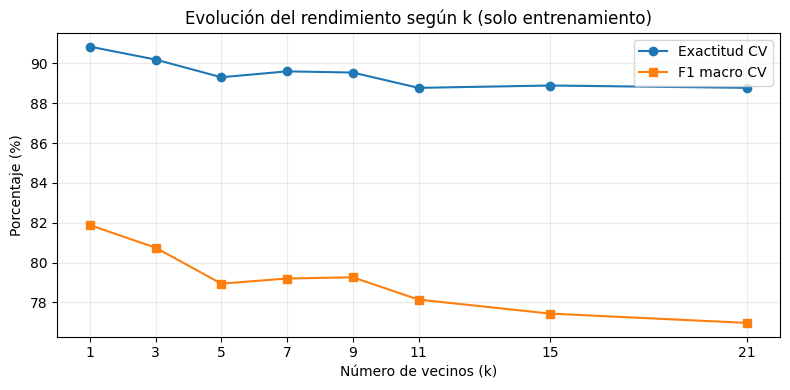

In [5]:
# Análisis de evolución del rendimiento al modificar el número de vecinos
plt.figure(figsize=(8, 4))
plt.plot(comparacion["k"], comparacion["Exactitud CV (%)"], marker="o", label="Exactitud CV")
plt.plot(comparacion["k"], comparacion["F1 macro CV (%)"], marker="s", label="F1 macro CV")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("Porcentaje (%)")
plt.title("Evolución del rendimiento según k (solo entrenamiento)")
plt.xticks(k_values)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

#### Análisis y Conclusiones Finales del Modelo (KNN)

Se aplicó el clasificador **KNN** con una partición de **80% de entrenamiento y 20% de prueba** (`seed=42`). Antes de dividir los datos se eliminaron los registros duplicados y se estandarizaron las características utilizando únicamente estadísticas del entrenamiento.

Mediante validación cruzada interna se seleccionó **k = 1**. En el conjunto de prueba, el modelo obtuvo una **exactitud de 89.81%** y un **F1 macro de 82.39%**.

La exactitud global indica un desempeño favorable, pero el **F1 macro** y el **Recall por clase** son necesarios para valorar los resultados en las categorías minoritarias. Además, el valor **k = 1** puede ser sensible a observaciones particulares, por lo que los resultados deben interpretarse considerando esa limitación.

**Nota:** Este modelo se utiliza únicamente con fines académicos.